# StudyMate · Part 5 of 8: Dev Evaluation and Feature Importance

**Assignment part:** Evaluation (dev set) & Feature Importance  
**Group 7:** Sadia Saeed · Eva Abouabouharb · Neida Guzman

50 practice (dev) questions are used to choose the search design (hybrid only vs two-stage vs reranker on all) with a rule written beforehand, and to check the guard. Cell 7b measures **feature importance**: each signal alone vs combined, plus weight tests.

> 📖 **This notebook is for reading.** It is one section of the full notebook, with the real outputs kept. Each part uses results from the parts before it, so to **run** StudyMate, open [`FN_StudyMate_Group7_ITAI2377.ipynb`](FN_StudyMate_Group7_ITAI2377.ipynb) and use **Runtime → Run all**.

## 6. Dev Questions (for Improving StudyMate)

**Purpose:** A labeled practice set to compare search options and check the off-topic guard.

**What's in it:**
- 46 beginner questions: one for each of the 16 dictionary lessons and 30 of the core lessons, written in beginner wording (not copied from the lessons).
- 4 off-topic questions labeled `NONE`, to test whether StudyMate correctly says "Sorry."
- `also_acceptable` lists a second lesson when it is also a fair answer.

**Note:** These questions were drafted with AI assistance and checked by our team. They are used only for development. The final test uses real questions from Data Science Stack Exchange.

**Output:** `dev_questions.csv` saved to Drive, plus a check that every label matches a real lesson title.

In [39]:
# CODE CELL 6 — DEV QUESTIONS
dev_rows = [
    # Dictionary lessons
    ("What makes deep learning different from regular machine learning?", "Deep Learning", "Neural Network Basics"),
    ("Which method lowers a model's error by taking small steps in the direction that improves it?", "Gradient Descent", ""),
    ("What happens if my model takes steps that are too big while it trains?", "Learning Rate", "Gradient Descent"),
    ("How does a neural network figure out which weights caused its mistake?", "Backpropagation", ""),
    ("Can I reuse a model trained on one task to help with a new task?", "Transfer Learning", "Fine-tuning"),
    ("How do I adjust a pretrained model a little bit using my own small dataset?", "Fine-tuning", "Transfer Learning"),
    ("How can a model learn without human labels by hiding parts of the data and guessing them?", "Self-Supervised Learning", "Unsupervised Learning"),
    ("How does a classifier turn its raw scores into probabilities that add up to 1?", "Softmax Function", "Activation Functions"),
    ("What neural network design reads a whole sentence at once instead of word by word?", "Transformer", "Attention Mechanism"),
    ("How does a model decide which words in a sentence matter most to each other?", "Attention Mechanism", "Transformer"),
    ("How can words be turned into lists of numbers so similar words end up close together?", "Embedding", ""),
    ("Why does a language model split text into small pieces before reading it?", "Token", ""),
    ("What are the settings I choose before training, like the number of layers?", "Hyperparameter", "Model Improvement"),
    ("How can I make more training images by flipping or rotating the ones I already have?", "Data Augmentation", ""),
    ("Why does a chatbot sometimes make up facts that sound true?", "Hallucination", ""),
    ("What kind of AI creates new text, images, or music?", "Generative AI", ""),
    # Core lessons
    ("What does it mean when we say a computer learns from data?", "What is Machine Learning?", ""),
    ("Is every AI system a machine learning system?", "AI vs ML", ""),
    ("What kind of learning uses examples that already have the correct answers?", "Supervised Learning", ""),
    ("How can a model find patterns when the data has no answers at all?", "Unsupervised Learning", "Clustering"),
    ("How can a game-playing AI learn from rewards and penalties?", "Reinforcement Learning", ""),
    ("How should I fix typos and duplicate rows before training?", "Data Cleaning", "Missing Values"),
    ("What should I do with empty cells in my dataset?", "Missing Values", "Data Cleaning"),
    ("Why should I put my columns on similar number ranges?", "Feature Scaling", ""),
    ("Why do we keep some data aside and never train on it?", "Train-Test Split", ""),
    ("What should I do with values that are far away from the rest?", "Outliers", ""),
    ("How do I turn a column of city names into numbers?", "One-Hot Encoding", ""),
    ("Which model fits a straight line to predict a price?", "Linear Regression", "Building a Regression Model"),
    ("Which simple model predicts the chance of a yes or no answer?", "Logistic Regression", ""),
    ("Which model asks a series of yes/no questions to reach a decision?", "Decision Trees", ""),
    ("How can a model classify something by looking at its closest examples?", "K-Nearest Neighbors", ""),
    ("What do we call many decision trees voting together?", "Random Forest", ""),
    ("What share of all predictions did my model get right?", "Accuracy", ""),
    ("When my model says 'spam', how often is it really spam?", "Precision", ""),
    ("How many of the real fraud cases did my model catch?", "Recall", ""),
    ("Which single score balances precision and recall?", "F1 Score", ""),
    ("How can I see all four kinds of right and wrong predictions in one table?", "Confusion Matrix", ""),
    ("My model memorized the training data. What is this problem called?", "Overfitting", ""),
    ("My model is too simple and performs badly everywhere. What's wrong?", "Underfitting", ""),
    ("How can I test my model on several different splits of the data?", "Cross-Validation", ""),
    ("What technique keeps model weights small to reduce overfitting?", "Regularization", "Overfitting"),
    ("Why is my test score unrealistically high when test information slipped into training?", "Data Leakage", ""),
    ("Which algorithm groups data into K clusters using center points?", "K-Means", "Clustering"),
    ("How can I reduce 50 columns to just a few while keeping the important information?", "PCA", ""),
    ("Why do neural networks use functions like ReLU?", "Activation Functions", ""),
    ("What is one full pass through all the training data called?", "Epochs and Batches", ""),
    # Off-topic (StudyMate should say "Sorry")
    ("How do I bake chocolate chip cookies?", "NONE", ""),
    ("Who won the last soccer World Cup?", "NONE", ""),
    ("What is a good name for a pet cat?", "NONE", ""),
    ("How do I fix a flat bike tire?", "NONE", ""),
]

dev = pd.DataFrame(dev_rows, columns=["question", "expected_lesson", "also_acceptable"])
dev.insert(0, "question_id", [f"D{i+1:02d}" for i in range(len(dev))])

# Check: every label must match a real lesson title
titles = set(lib["title"])
labels = set(dev["expected_lesson"]) | set(dev["also_acceptable"])
unknown = labels - titles - {"NONE", ""}
print("Unknown lesson labels:", unknown if unknown else "none")

dev.to_csv(os.path.join(project_path, "data", "evaluation", "dev_questions.csv"), index=False)
print(f"Saved {len(dev)} dev questions: {(dev['expected_lesson'] != 'NONE').sum()} ML + "
      f"{(dev['expected_lesson'] == 'NONE').sum()} off-topic")

Unknown lesson labels: none
Saved 50 dev questions: 46 ML + 4 off-topic


## 7. Compare Search Options on the Dev Questions

**Purpose:** Decide which search design StudyMate should use, and check the off-topic guard.

**Options compared (on the 46 ML dev questions):**
- **A. Hybrid only:** TF-IDF (30%) + embeddings (70%) → top 3.
- **B. Two-stage:** hybrid top 5 → cross-encoder reranker → 50/50 score fusion → top 3.
- **C. Reranker on all lessons:** the cross-encoder scores all 66 lessons → top 3.

**Decision rules (set before running):** Start with the simplest option (A). Use B only if it beats A by at least 2 questions on Top-1. Use C only if it beats the chosen option by at least 2 questions.

**Guard check:** Off-topic questions should score below the threshold (0), and ML questions above it.

**Output:** Top-1, Recall@3, lenient Top-1, and average time for each option; the decision; the guard scores; and the remaining mistakes.

In [40]:
# CODE CELL 7 — COMPARE SEARCH OPTIONS ON THE DEV QUESTIONS
def top3_hybrid(q):
    s = hybrid_scores(q)
    return lib["title"].iloc[np.argsort(-s)[:3]].tolist()

def top3_two_stage(q):
    return search(q)["title"].tolist()

def top3_rerank_all(q):
    s = reranker.predict([(q, t) for t in lib["search_text"]])
    return lib["title"].iloc[np.argsort(-s)[:3]].tolist()

options = {"A. Hybrid only": top3_hybrid,
           "B. Two-stage": top3_two_stage,
           "C. Reranker on all": top3_rerank_all}

ml_dev = dev[dev["expected_lesson"] != "NONE"]
rows = []
for name, fn in options.items():
    for _, q in ml_dev.iterrows():
        start = time.time()
        top3 = fn(q["question"])
        ok = [q["expected_lesson"]] + [a for a in [q["also_acceptable"]] if a]
        rows.append({"Option": name, "Question": q["question"], "Expected": q["expected_lesson"],
                     "Predicted": top3[0], "Top-1": int(top3[0] == q["expected_lesson"]),
                     "Recall@3": int(q["expected_lesson"] in top3),
                     "Top-1 (lenient)": int(top3[0] in ok), "Seconds": time.time() - start})

results = pd.DataFrame(rows)
summary = results.groupby("Option").agg(**{
    "Top-1 %": ("Top-1", lambda x: round(x.mean() * 100, 1)),
    "Recall@3 %": ("Recall@3", lambda x: round(x.mean() * 100, 1)),
    "Top-1 lenient %": ("Top-1 (lenient)", lambda x: round(x.mean() * 100, 1)),
    "Top-1 correct": ("Top-1", "sum"),
    "Avg seconds": ("Seconds", lambda x: round(x.mean(), 2))})
print(f"=== Dev evaluation: {len(ml_dev)} ML questions ===")
display(summary)

# Decision rules (set before running)
n = summary["Top-1 correct"]
choice = "A. Hybrid only"
if n["B. Two-stage"] - n[choice] >= 2:
    choice = "B. Two-stage"
if n["C. Reranker on all"] - n[choice] >= 2:
    choice = "C. Reranker on all"
print(f"\nDecision: {choice}")

# Off-topic guard check (same rule as answer() in Cell 5)
guard = pd.DataFrame([{"Question": q["question"], "Off-topic?": q["expected_lesson"] == "NONE",
                       "Blocked?": is_off_topic(q["question"])[0]} for _, q in dev.iterrows()])
off, on = guard[guard["Off-topic?"]], guard[~guard["Off-topic?"]]
print(f"\nGuard: off-topic blocked {off['Blocked?'].sum()} of {len(off)} | "
      f"ML questions wrongly blocked {on['Blocked?'].sum()} of {len(on)}")

print(f"\nRemaining mistakes for {choice}:")
display(results[(results["Option"] == choice) & (results["Top-1"] == 0)]
        [["Question", "Expected", "Predicted", "Recall@3", "Top-1 (lenient)"]])

results.to_csv(os.path.join(project_path, "data", "evaluation", "dev_option_results.csv"), index=False)

=== Dev evaluation: 46 ML questions ===


,Top-1 %,Recall@3 %,Top-1 lenient %,Top-1 correct,Avg seconds
Option,,,,,
A. Hybrid only,65.2,95.7,67.4,30,0.05
B. Two-stage,71.7,95.7,76.1,33,0.06
C. Reranker on all,71.7,84.8,76.1,33,0.15



Decision: B. Two-stage

Guard: off-topic blocked 4 of 4 | ML questions wrongly blocked 0 of 46

Remaining mistakes for B. Two-stage:


,Question,Expected,Predicted,Recall@3,Top-1 (lenient)
49,How does a neural network figure out which weights caused its mistake?,Backpropagation,Neurons and Weights,1,0
52,How can a model learn without human labels by hiding parts of the data and guessing them?,Self-Supervised Learning,Unsupervised Learning,1,1
54,What neural network design reads a whole sentence at once instead of word by word?,Transformer,Token,1,0
63,Is every AI system a machine learning system?,AI vs ML,What is Machine Learning?,1,0
68,What should I do with empty cells in my dataset?,Missing Values,Data Cleaning,1,1
69,Why should I put my columns on similar number ranges?,Feature Scaling,Embedding,1,0
71,What should I do with values that are far away from the rest?,Outliers,Missing Values,1,0
72,How do I turn a column of city names into numbers?,One-Hot Encoding,Embedding,1,0
73,Which model fits a straight line to predict a price?,Linear Regression,R-Squared,1,0
74,Which simple model predicts the chance of a yes or no answer?,Logistic Regression,Accuracy,0,0


## Step 7b: Feature importance — which signals find the right lesson?
**Our engineered features:**
1. **`search_text`**: one combined text field per lesson (title + topic + explanations + related terms)
2. **TF-IDF score**: word matching (do the question and the lesson share exact words?)
3. **Embedding score**: meaning matching (all-MiniLM-L6-v2, 384 numbers per text)
4. **Hybrid score**: 30% words + 70% meaning (Judge 1)
5. **Reranker score**: the cross-encoder reads the question and the lesson together (Judge 2)
6. **`final_score`**: 50% hybrid + 50% reranker, each scaled 0–1 (min-max normalization)

**How we measure importance:** we use each signal alone and then combined on the 46 dev ML questions, and check
how often the right lesson comes first (Top-1) or lands in the top 3 (Recall@3). We also test different weights.
**Note:** this is analysis only. No settings are changed, because the final exam (Cell 10) is already done.

ML dev questions: 46
Rebuilt hybrid matches Cell 4: True

=== Feature importance: each signal alone vs combined ===


,Top-1 %,Recall@3 %
TF-IDF only (words),54.3,69.6
Embedding only (meaning),65.2,89.1
Hybrid 30/70 (Judge 1),65.2,95.7
Two-stage (final_score),71.7,95.7


TF-IDF weight test (Top-1 %):   {0: 65.2, 0.3: 65.2, 0.5: 69.6, 0.7: 63.0, 1.0: 54.3}
Reranker weight test (Top-1 %): {0: 65.2, 0.25: 67.4, 0.5: 71.7, 0.75: 76.1, 1.0: 71.7}

Normalization example:


,title,rerank_score,scaled_0_to_1
0,F1 Score,3.852513,1.000
1,Recall,0.997756,0.809
2,Precision,1.128170,0.817
3,Accuracy,-5.635601,0.364
4,Confusion Matrix,-11.072486,0.000


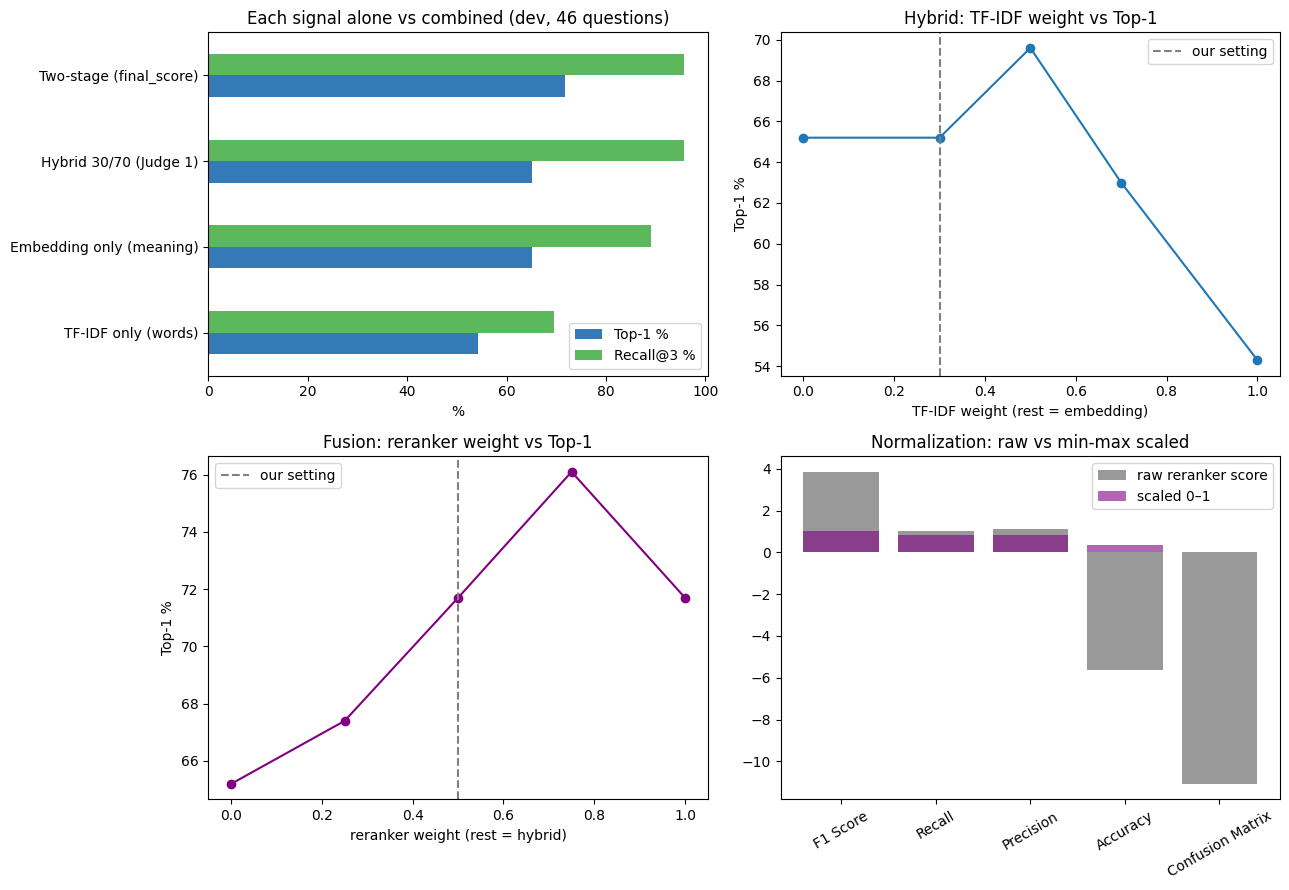

In [41]:
# CELL 7b — FEATURE IMPORTANCE (analysis only, dev questions)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

fig_dir = f"{project_path}/figures"

# ---- load the 46 dev ML questions (skip the 4 off-topic ones) ----
dev = pd.read_csv(f"{project_path}/data/evaluation/dev_questions.csv")
ml_dev = dev[dev["expected_lesson"] != "NONE"].reset_index(drop=True)
print("ML dev questions:", len(ml_dev))
titles = lib["title"].values

# ---- features 2 and 3: TF-IDF and embedding scores (same as Cell 4) ----
cache = {}
def tf_em(q):
    """Return (TF-IDF scores, embedding scores) for one question against all 66 lessons."""
    if q not in cache:
        tf = cosine_similarity(tfidf_vectorizer.transform([q]), tfidf_matrix).flatten()
        q_emb = embedding_model.encode([q], convert_to_numpy=True, normalize_embeddings=True)
        em = cosine_similarity(q_emb, lesson_embeddings).flatten()
        cache[q] = (tf, em)
    return cache[q]

# safety check: 0.3 × TF-IDF + 0.7 × embedding must equal the real hybrid from Cell 4
q0 = ml_dev["question"][0]
tf0, em0 = tf_em(q0)
print("Rebuilt hybrid matches Cell 4:", np.allclose(0.3 * tf0 + 0.7 * em0, hybrid_scores(q0), atol=1e-6))

# ---- grading helper: Top-1 % and Recall@3 % ----
top3 = lambda s: list(titles[np.argsort(-np.asarray(s))[:3]])
def grade(rank_fn):
    hits1 = hits3 = 0
    for q, exp in zip(ml_dev["question"], ml_dev["expected_lesson"]):
        t3 = rank_fn(q)
        hits1 += t3[0] == exp
        hits3 += exp in t3
    n = len(ml_dev)
    return round(100 * hits1 / n, 1), round(100 * hits3 / n, 1)

# ---- A) each signal alone vs combined ----
ablation = pd.DataFrame({
    "TF-IDF only (words)":      grade(lambda q: top3(tf_em(q)[0])),
    "Embedding only (meaning)": grade(lambda q: top3(tf_em(q)[1])),
    "Hybrid 30/70 (Judge 1)":   grade(lambda q: top3(hybrid_scores(q))),
    "Two-stage (final_score)":  grade(lambda q: list(search(q)["title"])),
}, index=["Top-1 %", "Recall@3 %"]).T
print("\n=== Feature importance: each signal alone vs combined ===")
display(ablation)

# ---- B) weight tests: how much say should each signal get? ----
tf_w = [0, 0.3, 0.5, 0.7, 1.0]          # TF-IDF weight inside hybrid (we use 0.3)
tf_sweep = [grade(lambda q, a=a: top3(a * tf_em(q)[0] + (1 - a) * tf_em(q)[1]))[0] for a in tf_w]
rr_w = [0, 0.25, 0.5, 0.75, 1.0]        # reranker weight in fusion (we use 0.5)
rr_sweep = [grade(lambda q, w=w: list(search(q, w_rerank=w)["title"]))[0] for w in rr_w]
print("TF-IDF weight test (Top-1 %):  ", dict(zip(tf_w, tf_sweep)))
print("Reranker weight test (Top-1 %):", dict(zip(rr_w, rr_sweep)))

# ---- C) normalization example: raw reranker scores vs 0–1 scaled ----
ex = search("What is the difference between precision and recall?", top_n=5)
print("\nNormalization example:")
display(ex[["title", "rerank_score"]].assign(scaled_0_to_1=minmax(ex["rerank_score"].values).round(3)))

# ---- 4 charts ----
fig, ax = plt.subplots(2, 2, figsize=(13, 9))

ablation.plot.barh(ax=ax[0, 0], color=["#337ab7", "#5cb85c"])
ax[0, 0].set_title("Each signal alone vs combined (dev, 46 questions)"); ax[0, 0].set_xlabel("%")

ax[0, 1].plot(tf_w, tf_sweep, "o-")
ax[0, 1].axvline(0.3, ls="--", c="gray", label="our setting")
ax[0, 1].set_title("Hybrid: TF-IDF weight vs Top-1")
ax[0, 1].set_xlabel("TF-IDF weight (rest = embedding)"); ax[0, 1].set_ylabel("Top-1 %"); ax[0, 1].legend()

ax[1, 0].plot(rr_w, rr_sweep, "o-", c="purple")
ax[1, 0].axvline(0.5, ls="--", c="gray", label="our setting")
ax[1, 0].set_title("Fusion: reranker weight vs Top-1")
ax[1, 0].set_xlabel("reranker weight (rest = hybrid)"); ax[1, 0].set_ylabel("Top-1 %"); ax[1, 0].legend()

ax[1, 1].bar(ex["title"], ex["rerank_score"], color="#999999", label="raw reranker score")
ax[1, 1].bar(ex["title"], minmax(ex["rerank_score"].values), color="purple", alpha=0.6, label="scaled 0–1")
ax[1, 1].set_title("Normalization: raw vs min-max scaled")
ax[1, 1].tick_params(axis="x", rotation=30); ax[1, 1].legend()

plt.tight_layout()
plt.savefig(f"{fig_dir}/feature_importance.png", dpi=150)
plt.show()
ablation.to_csv(f"{project_path}/data/evaluation/feature_importance.csv")
